# B28 怎样把训练好的模型做成可调用的预测接口？

任务：保存、重新加载教学租金模型，用 FastAPI 提供本地接口，并实际发送有效与无效请求。

先修：B07、B10；序列化、输入校验与 HTTP。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 固定特征顺序与目标单位
租金由面积、房间数、楼层和噪声生成。输入顺序是服务契约的一部分；测试数据不参与训练。这不是实际房价模型。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
rng = np.random.default_rng(28)
X = np.column_stack([rng.uniform(25, 180, 500), rng.integers(1, 6, 500), rng.integers(1, 25, 500)])
y = 600 + 15 * X[:, 0] + 180 * X[:, 1] + 4 * X[:, 2] + rng.normal(0, 70, 500)
model = RandomForestRegressor(n_estimators=60, max_depth=8, random_state=28, n_jobs=1).fit(X[:380], y[:380])
mae = float(mean_absolute_error(y[380:], model.predict(X[380:])))
feature_names = ['area', 'rooms', 'floor']

## 2. 保存与重载一致性
joblib 只能加载可信文件。保存后重载，同一输入的输出必须一致；另存特征顺序、数据性质和目标单位，防止交接时只剩一个无说明的二进制文件。

In [3]:
joblib.dump(model, OUT_DIR / 'model.joblib')
loaded = joblib.load(OUT_DIR / 'model.joblib')
assert np.allclose(loaded.predict(X[380:385]), model.predict(X[380:385]))
(OUT_DIR / 'model_metadata.json').write_text(json.dumps({'features': feature_names, 'model_version': 'teaching-v1', 'data': 'synthetic', 'target_unit': '教学货币/月'}, ensure_ascii=False, indent=2), encoding='utf-8')

144

## 3. 输入校验与响应
Pydantic 限制字段、数值范围和额外字段；非法请求返回422，不进入模型。api.py 是同一接口的独立入口，只在127.0.0.1启动。

In [4]:
from fastapi import FastAPI
from pydantic import BaseModel, Field, ConfigDict

class RentRequest(BaseModel):
    model_config = ConfigDict(extra='forbid', allow_inf_nan=False)
    area: float = Field(gt=0, le=500)
    rooms: int = Field(ge=1, le=10)
    floor: int = Field(ge=1, le=80)

def create_app(estimator):
    app = FastAPI(title='教学租金预测 API')

    @app.get('/health')
    def health():
        return {'status': 'ok', 'model_version': 'teaching-v1'}

    @app.post('/predict')
    def predict(payload: RentRequest):
        value = max(0.0, float(estimator.predict([[payload.area, payload.rooms, payload.floor]])[0]))
        return {'predicted_rent': round(value, 2), 'unit': '教学货币/月', 'model_version': 'teaching-v1'}
    return app
app = create_app(loaded)

## 4. 通过真实路由测试契约
TestClient 走 FastAPI 路由和验证，不只是调用预测函数。检查健康、正常请求、负面积和额外字段；接口正确不代表模型在真实业务中准确。

In [5]:
from fastapi.testclient import TestClient
with TestClient(app) as client:
    health = client.get('/health')
    valid = client.post('/predict', json={'area': 80, 'rooms': 3, 'floor': 5})
    invalid = client.post('/predict', json={'area': -1, 'rooms': 3, 'floor': 5})
    extra = client.post('/predict', json={'area': 80, 'rooms': 3, 'floor': 5, 'secret': 1})
assert health.status_code == valid.status_code == 200 and invalid.status_code == extra.status_code == 422
assert valid.json()['predicted_rent'] >= 0
(OUT_DIR / 'api_responses.json').write_text(json.dumps({'valid': valid.json(), 'invalid_status': invalid.status_code, 'extra_field_status': extra.status_code}, ensure_ascii=False, indent=2), encoding='utf-8')
barplot(['正常预测', '负面积', '额外字段'], [valid.status_code, invalid.status_code, extra.status_code], '实际 HTTP 状态码')
finish({'test_mae': mae, 'valid_request_status': valid.status_code, 'invalid_request_status': invalid.status_code, 'serialization_match': True, 'sample_prediction': valid.json()})

{
  "test_mae": 74.54137711788938,
  "valid_request_status": 200,
  "invalid_request_status": 422,
  "serialization_match": true,
  "sample_prediction": {
    "predicted_rent": 2399.72,
    "unit": "教学货币/月",
    "model_version": "teaching-v1"
  },
  "elapsed_seconds": 1.209
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

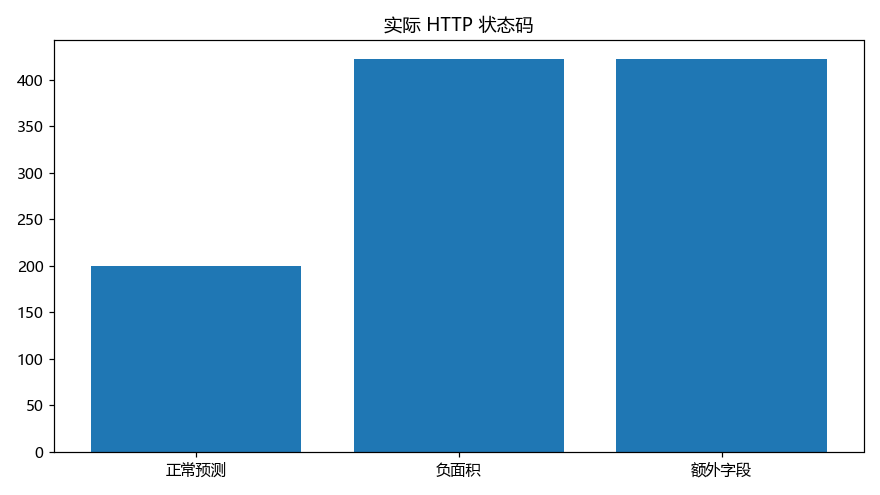

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
只用于本地教学；真实服务还需要鉴权、日志与监测。只载入可信序列化文件。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。